# **Fine-tuning a pretrained ViT-B/16 on CIFAR-10 (target: 98%+)**
Runs 1-4 trained from scratch; the best was ResNet-18 with AutoAugment + CutMix at 96.83% (`assignment_2_resnet_run4.ipynb`).
Training from scratch tops out around 97-98% even with much bigger networks and many hours of training, so this run uses
**transfer learning**: a Vision Transformer (ViT-B/16, 86M params) pretrained with SWAG weakly-supervised learning on
3.6B Instagram images and then ImageNet, with its classifier replaced by a 10-class head and the whole network fine-tuned.

- CIFAR images (32x32) are upscaled to the 224x224 resolution the model was pretrained on (on the GPU, after augmentation).
- ImageNet normalization statistics, since that's what the pretrained weights expect.
- AdamW with a small learning rate (pretrained weights only need small adjustments), OneCycle schedule, 10 epochs.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.models import vit_b_16, ViT_B_16_Weights
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = True
print(device, torch.cuda.get_device_name(0) if device == "cuda" else "")

c:\Users\Admin\Documents\GitHub\DL-Assignment2-CNN-CIFAR\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda NVIDIA GeForce RTX 4080 SUPER


# **Data**

In [2]:
IMG_SIZE = 224                                          # resolution the pretrained model expects
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

# augmentation happens at 32x32 on the CPU; upscaling + normalization happen on the GPU (see to_model_input)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
])
test_transform = transforms.ToTensor()

train_dataset = datasets.CIFAR10(root="../dataset", train=True, download=True, transform=train_transform)
test_dataset = datasets.CIFAR10(root="../dataset", train=False, download=True, transform=test_transform)

train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    dataset=test_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True
)
classes = train_dataset.classes

def to_model_input(images):
    """32x32 [0,1] batch on GPU -> 224x224 ImageNet-normalized batch"""
    images = F.interpolate(images, size=IMG_SIZE, mode="bilinear", align_corners=False)
    return (images - IMAGENET_MEAN) / IMAGENET_STD

print(f"Train length: {len(train_dataset)}\nTest length: {len(test_dataset)}\nClasses: {classes}")

Train length: 50000
Test length: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


# **Model: pretrained ViT-B/16 with a new 10-class head**

In [3]:
def build_model():
    model = vit_b_16(weights=ViT_B_16_Weights.IMAGENET1K_SWAG_LINEAR_V1)   # downloads ~330MB once
    model.heads.head = nn.Linear(model.heads.head.in_features, 10)        # 768 -> 10 classes
    nn.init.zeros_(model.heads.head.weight)                                # start from uniform predictions
    nn.init.zeros_(model.heads.head.bias)
    return model.to(device)

print(f"Parameters: {sum(p.numel() for p in build_model().parameters()) / 1e6:.1f}M")

Parameters: 85.8M


# **Training and Evaluation**

In [4]:
AMP_DTYPE = torch.bfloat16

def train_one_epoch(model, loader, optimizer, criterion, scheduler=None):
    model.train()
    total_loss, correct, total = 0, 0, 0
    for images, labels in tqdm(loader, desc="Training", leave=False):
        images = to_model_input(images.to(device, non_blocking=True))
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
            outputs = model(images)
            loss = criterion(outputs, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # keeps fine-tuning stable
        optimizer.step()
        if scheduler is not None:
            scheduler.step()
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

def evaluate(model, loader, criterion, tta=True):
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images = to_model_input(images.to(device, non_blocking=True))
            labels = labels.to(device, non_blocking=True)
            with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
                outputs = model(images)
                if tta:                                 # average with horizontally flipped images
                    outputs = (outputs + model(torch.flip(images, dims=[3]))) / 2
                loss = criterion(outputs, labels)
            total_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

def fit(model, train_loader, test_loader, epochs, optimizer, criterion, scheduler):
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}
    for epoch in range(epochs):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, optimizer, criterion, scheduler)
        te_loss, te_acc = evaluate(model, test_loader, criterion)
        history["train_loss"].append(tr_loss); history["train_acc"].append(tr_acc)
        history["test_loss"].append(te_loss);  history["test_acc"].append(te_acc)
        print(f"Epoch {epoch+1}/{epochs} | train loss {tr_loss:.4f} | train acc {tr_acc:.4f} | "
              f"test loss {te_loss:.4f} | test acc {te_acc:.4f}")
    return history

def plot_history(history, title=""):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, history["train_loss"], label="train loss")
    ax1.plot(epochs, history["test_loss"], label="test loss")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend()
    ax2.plot(epochs, history["train_acc"], label="train acc")
    ax2.plot(epochs, history["test_acc"], label="test acc")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.legend()
    fig.suptitle(title)
    plt.show()

# **Fine-tune**

Epoch 1/10 | train loss 1.2594 | train acc 0.8908 | test loss 0.9894 | test acc 0.7877


Epoch 2/10 | train loss 0.7395 | train acc 0.8969 | test loss 0.6804 | test acc 0.9204


Epoch 3/10 | train loss 0.6735 | train acc 0.9244 | test loss 0.6528 | test acc 0.9298


Epoch 4/10 | train loss 0.6304 | train acc 0.9431 | test loss 0.6274 | test acc 0.9474


Epoch 5/10 | train loss 0.5993 | train acc 0.9574 | test loss 0.5958 | test acc 0.9595


Epoch 6/10 | train loss 0.5639 | train acc 0.9717 | test loss 0.5956 | test acc 0.9596


Epoch 7/10 | train loss 0.5395 | train acc 0.9833 | test loss 0.5698 | test acc 0.9730


Epoch 8/10 | train loss 0.5203 | train acc 0.9917 | test loss 0.5661 | test acc 0.9746


Epoch 9/10 | train loss 0.5085 | train acc 0.9967 | test loss 0.5594 | test acc 0.9782


Epoch 10/10 | train loss 0.5057 | train acc 0.9980 | test loss 0.5593 | test acc 0.9780


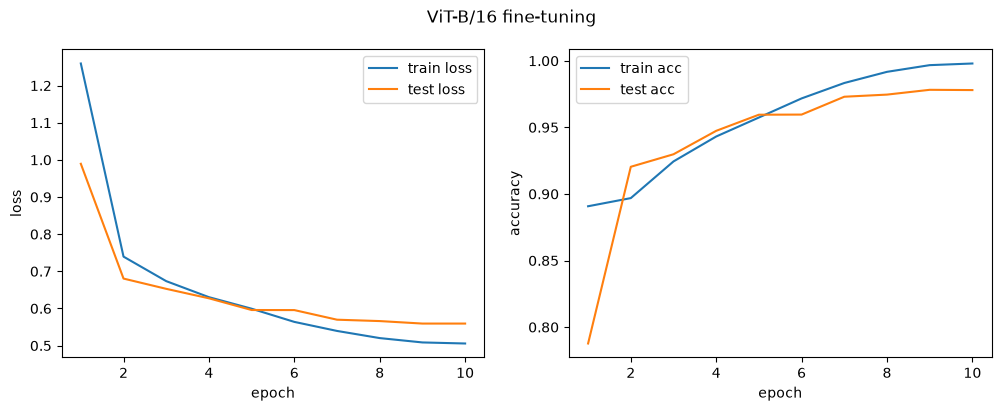

In [5]:
EPOCHS = 10
model = build_model()
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.05)
scheduler = optim.lr_scheduler.OneCycleLR(optimizer, max_lr=5e-5, epochs=EPOCHS, pct_start=0.1,
                                          steps_per_epoch=len(train_loader))
history = fit(model, train_loader, test_loader, EPOCHS, optimizer, criterion, scheduler)
plot_history(history, "ViT-B/16 fine-tuning")
torch.save(model.state_dict(), "vit_b16_cifar10.pth")

# **Final Results**

In [6]:
_, acc_plain = evaluate(model, test_loader, criterion, tta=False)
_, acc_tta = evaluate(model, test_loader, criterion, tta=True)
print(f"Test accuracy without TTA: {acc_plain:.4f}")
print(f"Test accuracy with flip TTA: {acc_tta:.4f}")

# per-class accuracy
model.eval()
class_correct, class_total = torch.zeros(10), torch.zeros(10)
with torch.no_grad():
    for images, labels in test_loader:
        images = to_model_input(images.to(device))
        with torch.autocast(device_type="cuda", dtype=AMP_DTYPE):
            outputs = model(images) + model(torch.flip(images, dims=[3]))
        preds = outputs.argmax(1).cpu()
        for c in range(10):
            mask = labels == c
            class_correct[c] += (preds[mask] == c).sum()
            class_total[c] += mask.sum()
for c, name in enumerate(classes):
    print(f"{name:>10}: {class_correct[c] / class_total[c]:.4f}")

Test accuracy without TTA: 0.9772
Test accuracy with flip TTA: 0.9780
  airplane: 0.9870
automobile: 0.9890
      bird: 0.9720
       cat: 0.9470
      deer: 0.9780
       dog: 0.9660
      frog: 0.9920
     horse: 0.9830
      ship: 0.9870
     truck: 0.9790
